<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day04_Baselines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Today we'll build the first two methods, random and greedy, and learn three simple numbers for judging any matching. Every smarter method later has to beat these two, so they matter more than they look.

Two ideas for today

Idea 1: baselines. A baseline is a simple method that sets the bar. Random hands out places without looking at anyone's wishes, and greedy goes through the students in a line, giving each their best-scoring project that still has a free place. If a clever method can't beat these, it isn't worth the effort.

Idea 2: judge a matching with several numbers, not one. An average can hide that a few students got a terrible outcome. We'll use:

Average happiness: the mean score of the projects people received.
Top-3 %: the share of students who got one of their top three choices.
Worst outcome: the lowest-ranked project anyone received.
One decision to make first

On Day 3 we noticed that a project a student never listed can outscore one they did list. Our rule for this programme: students are only placed on projects they listed. If all five of their choices are full, they get any free project, and we count that as "not on their list". The code below also runs the opposite rule (any project allowed), so you can see what the choice changes.

In [1]:
# Cell 1: fetch your earlier files if this is a fresh session
import os, subprocess
if not os.path.exists("scores.csv"):
    subprocess.run(["git", "clone", "-q", "https://github.com/buntyedutainer/allocation-optimizer", "repo"])
    subprocess.run("cp repo/data/*.csv .", shell=True)
print([f for f in ["scores.csv", "projects.csv", "preferences.csv"] if os.path.exists(f)])

['scores.csv', 'projects.csv', 'preferences.csv']


Save the tools in a file

In [2]:
%%writefile matching.py
"""Matching tools for the allocation project."""
import numpy as np
import pandas as pd

UNLISTED_RANK = 6          # the rank we give to a project the student did not list


def load():
    score = pd.read_csv("scores.csv", index_col=0)
    projects = pd.read_csv("projects.csv", index_col=0)
    prefs = pd.read_csv("preferences.csv")
    rank_table = (prefs.pivot(index="student_id", columns="project_id", values="rank")
                  .reindex(index=score.index, columns=score.columns).fillna(UNLISTED_RANK).astype(int))
    return score, projects, projects["capacity"].copy(), rank_table


def match_greedy(score, rank_table, capacity, order, listed_only=True):
    """Go through the students in 'order'. Each takes their best-scoring project that still has a place."""
    left = capacity.copy()
    result = {}
    for sid in order:
        options = score.loc[sid][left > 0]                          # projects with a free place
        if listed_only:
            on_list = options[rank_table.loc[sid, options.index] < UNLISTED_RANK]
            if len(on_list) > 0:                                    # otherwise: fall back to any free project
                options = on_list
        pick = options.idxmax()
        result[sid] = pick
        left[pick] -= 1
    return pd.Series(result)


def match_random(score, rank_table, capacity, order, rng, listed_only=True):
    """Go through the students in 'order'. Each gets a random project that still has a place."""
    left = capacity.copy()
    result = {}
    for sid in order:
        free = list(left[left > 0].index)
        if listed_only:
            on_list = [p for p in free if rank_table.loc[sid, p] < UNLISTED_RANK]
            if on_list:
                free = on_list
        pick = rng.choice(free)
        result[sid] = pick
        left[pick] -= 1
    return pd.Series(result)


def validate(assign, score, capacity):
    problems = []
    if set(assign.index) != set(score.index):
        problems.append("not every student is placed exactly once")
    over = [p for p, c in assign.value_counts().items() if c > capacity[p]]
    if over:
        problems.append(f"over capacity: {over}")
    return problems or ["valid"]


def outcomes(assign, score, rank_table):
    """One row per student: the project they got, its score, and the rank they gave it."""
    return pd.DataFrame({"project": assign,
                         "score": [score.loc[s, p] for s, p in assign.items()],
                         "rank": [rank_table.loc[s, p] for s, p in assign.items()]}, index=assign.index)


def summary(out):
    return {"average happiness": out["score"].mean(),
            "top-1 %": 100 * (out["rank"] == 1).mean(),
            "top-3 %": 100 * (out["rank"] <= 3).mean(),
            "not on their list %": 100 * (out["rank"] == UNLISTED_RANK).mean(),
            "worst rank": int(out["rank"].max()),
            "lowest happiness": out["score"].min()}

Writing matching.py


Load the data.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matching as M

score, projects, capacity, rank_table = M.load()
print(len(score), "students,", capacity.sum(), "places")
rank_table.iloc[:3, :5]       # the rank each student gave each project (6 = not listed)

40 students, 44 places


,P01,P02,P03,P04,P05
S01,1,5,2,6,6
S02,1,6,2,6,6
S03,1,2,3,6,6


Run all four variants once, in the same line-up order. Students go in ID order, S01 first. That's "first come, first served".

In [4]:
order = list(score.index)
rng = np.random.default_rng(1)

runs = {
    "Random (any project)": M.match_random(score, rank_table, capacity, order, rng, listed_only=False),
    "Random (listed only)": M.match_random(score, rank_table, capacity, order, rng, listed_only=True),
    "Greedy (any project)": M.match_greedy(score, rank_table, capacity, order, listed_only=False),
    "Greedy (listed only)": M.match_greedy(score, rank_table, capacity, order, listed_only=True),
}
for name, a in runs.items():
    print(f"{name:22s} {M.validate(a, score, capacity)}")

table = pd.DataFrame({name: M.summary(M.outcomes(a, score, rank_table)) for name, a in runs.items()}).T.round(1)
table

Random (any project)   ['valid']
Random (listed only)   ['valid']
Greedy (any project)   ['valid']
Greedy (listed only)   ['valid']


,average happiness,top-1 %,top-3 %,not on their list %,worst rank,lowest happiness
Random (any project),3.3,7.5,27.5,57.5,6.0,0.0
Random (listed only),4.8,17.5,27.5,7.5,6.0,1.0
Greedy (any project),4.8,15.0,30.0,17.5,6.0,1.0
Greedy (listed only),4.8,15.0,30.0,17.5,6.0,1.0


The line-up matters, so try 200 different orders. The greedy method gives different results when the students stand in a different order.

In [5]:
def repeat(fn, n=200, seed=0):
    rng = np.random.default_rng(seed)
    rows, by_position = [], []
    for _ in range(n):
        order = list(rng.permutation(score.index))                 # a new random line-up
        out = M.outcomes(fn(order, rng), score, rank_table)
        rows.append(M.summary(out))
        by_position.append(out.loc[order, "rank"].values)          # the rank each position in line received
    return pd.DataFrame(rows), np.array(by_position)

greedy_runs, greedy_pos = repeat(lambda o, r: M.match_greedy(score, rank_table, capacity, o))
random_runs, random_pos = repeat(lambda o, r: M.match_random(score, rank_table, capacity, o, r))

def spread(df):
    return pd.DataFrame({"mean": df.mean(), "min": df.min(), "max": df.max()}).round(1)

print("GREEDY (listed only), 200 random line-ups"); display(spread(greedy_runs))
print("RANDOM (listed only), 200 random line-ups"); display(spread(random_runs))

GREEDY (listed only), 200 random line-ups


,mean,min,max
average happiness,4.9,4.2,5.4
top-1 %,18.6,10.0,25.0
top-3 %,35.4,27.5,42.5
not on their list %,20.8,12.5,30.0
worst rank,6.0,6.0,6.0
lowest happiness,0.7,0.0,1.5


RANDOM (listed only), 200 random line-ups


,mean,min,max
average happiness,4.3,3.5,4.9
top-1 %,8.8,0.0,22.5
top-3 %,29.1,20.0,40.0
not on their list %,16.7,7.5,27.5
worst rank,6.0,6.0,6.0
lowest happiness,0.4,0.0,1.5


The same method, a very different result.

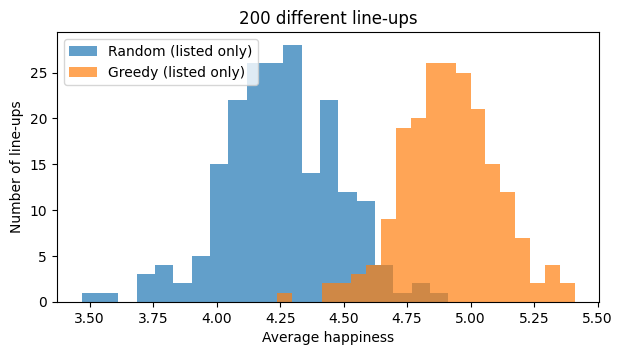

In [6]:
plt.figure(figsize=(7, 3.5))
plt.hist(random_runs["average happiness"], bins=20, alpha=0.7, label="Random (listed only)")
plt.hist(greedy_runs["average happiness"], bins=20, alpha=0.7, label="Greedy (listed only)")
plt.xlabel("Average happiness")
plt.ylabel("Number of line-ups")
plt.title("200 different line-ups")
plt.legend()
plt.show()

Does your place in line matter? For each position in the line, the average rank received (1 = favourite).

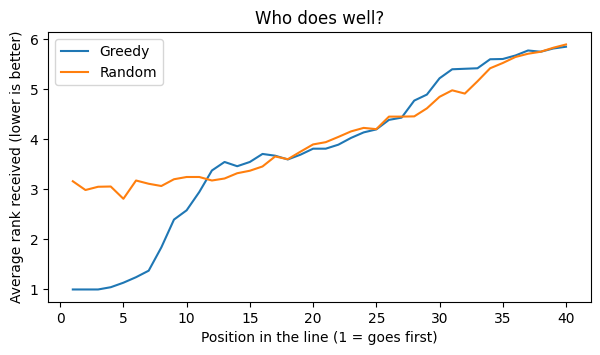

Greedy, average rank for the first 10 in line: 1.46
Greedy, average rank for the last 10 in line:  5.62


In [7]:
positions = np.arange(1, len(score) + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(positions, greedy_pos.mean(axis=0), label="Greedy")
plt.plot(positions, random_pos.mean(axis=0), label="Random")
plt.xlabel("Position in the line (1 = goes first)")
plt.ylabel("Average rank received (lower is better)")
plt.title("Who does well?")
plt.legend()
plt.show()

print("Greedy, average rank for the first 10 in line:", greedy_pos[:, :10].mean().round(2))
print("Greedy, average rank for the last 10 in line: ", greedy_pos[:, -10:].mean().round(2))

Save the results.

In [8]:
table.to_csv("baseline_single_run.csv")
spread(greedy_runs).to_csv("baseline_greedy_200_orders.csv")
spread(random_runs).to_csv("baseline_random_200_orders.csv")
print("Saved three CSV files")

Saved three CSV files
